# 3. Smudge and blot

Each effect changes an ink field into an ink field. An ink field is float32,
from 0 to 1, where 1 is full ink. The effects compose in any order, and
textsynth applies the colour one time, at the end.

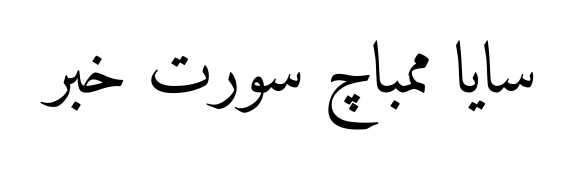

In [1]:
from textsynth import (
    Blot,
    ComponentFilter,
    Layout,
    Smudge,
    Synthesizer,
    image_to_ink,
    ink_to_image,
)
from nbutil import FONT, sheet

TEXT = "سايا ممباچ سورت خبر"
layout = Layout(size=72, tracking=-1, supersample=2)
clean = Synthesizer(font=FONT, layout=layout)
clean(TEXT)

## Smudge

`length` and `angle` set the size and the direction of the smear. `strength`
sets how much ink the smear adds. `fade` removes ink from the far end.

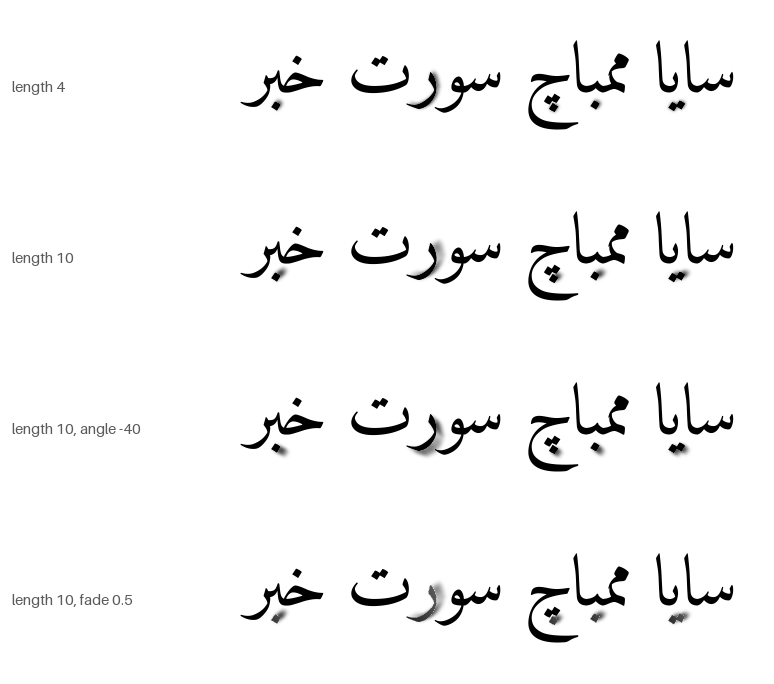

In [2]:
rows = []
for label, effect in (
    ("length 4", Smudge(length=4, strength=0.7)),
    ("length 10", Smudge(length=10, strength=0.7)),
    ("length 10, angle -40", Smudge(length=10, angle=-40, strength=0.7)),
    ("length 10, fade 0.5", Smudge(length=10, strength=0.7, fade=0.5)),
):
    rows.append((label, Synthesizer(font=FONT, layout=layout, effects=[effect], seed=4)(TEXT)))
sheet(rows, gutter=200)

`ComponentFilter` sets a minimum area, a maximum area, a count, and a
probability for each candidate. Every effect that selects components uses it.

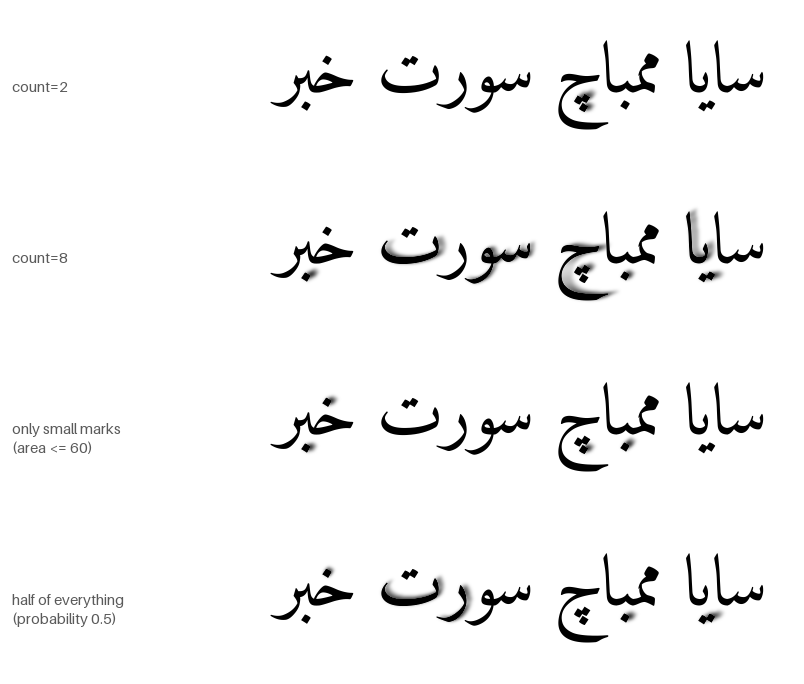

In [3]:
rows = []
for label, sel in (
    ("count=2", ComponentFilter(min_area=20, count=2)),
    ("count=8", ComponentFilter(min_area=20, count=8)),
    ("only small marks\n(area <= 60)", ComponentFilter(min_area=2, max_area=60)),
    ("half of everything\n(probability 0.5)", ComponentFilter(min_area=5, probability=0.5)),
):
    effect = Smudge(length=8, strength=0.75, select=sel)
    rows.append((label, Synthesizer(font=FONT, layout=layout, effects=[effect], seed=4)(TEXT)))
sheet(rows, gutter=230)

## Blot

`Blot` puts a solid copy of the mark next to it. Use it for a wet stroke that
moved, or for a double strike.

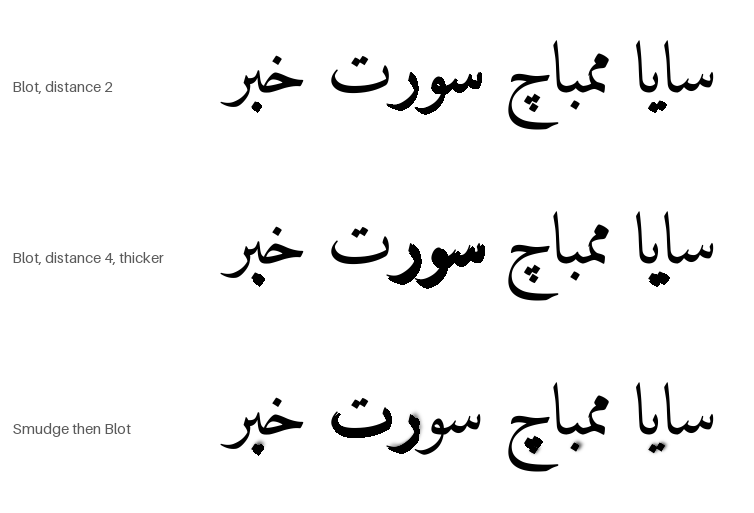

In [4]:
rows = []
for label, effect in (
    ("Blot, distance 2", Blot(distance=2)),
    ("Blot, distance 4, thicker", Blot(distance=4, thickness=1)),
    ("Smudge then Blot", None),
):
    if effect is None:
        effects = [Smudge(length=6, strength=0.7), Blot(distance=3)]
    else:
        effects = [effect]
    rows.append((label, Synthesizer(font=FONT, layout=layout, effects=effects, seed=4)(TEXT)))
sheet(rows, gutter=180)

## Direction, and a second pass

The default drags the ink one way. `spread="both"` spreads the ink along the
two directions.

`Smudge` takes the maximum ink value. A second pass adds no more ink.

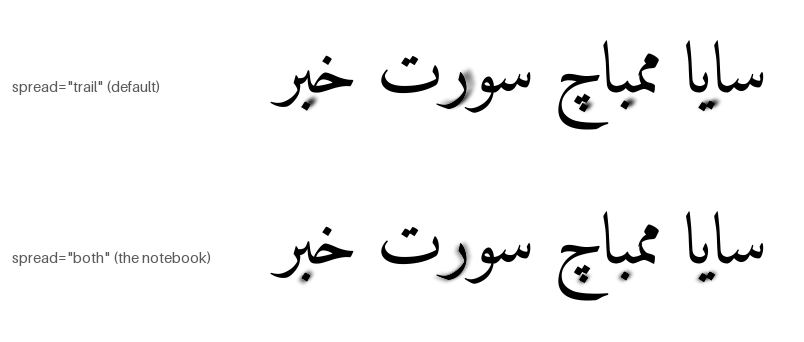

In [5]:
rows = [
    ('spread="trail" (default)', Smudge(length=10, strength=0.8, spread="trail")),
    ('spread="both" (the notebook)', Smudge(length=10, strength=0.8, spread="both")),
]
sheet([(label, Synthesizer(font=FONT, layout=layout, effects=[e], seed=4)(TEXT)) for label, e in rows], gutter=230)

In [6]:
import numpy as np

# Idempotent: applying it twice to the same field changes nothing the second
# time, because the effect takes a maximum rather than accumulating.
ink = image_to_ink(clean(TEXT))
once = Smudge(length=8).apply(ink, np.random.default_rng(0))
twice = Smudge(length=8).apply(once, np.random.default_rng(0))
print("max extra ink on a second pass:", float(np.abs(twice - once).max()))

max extra ink on a second pass: 0.2821832001209259


`image_to_ink` finds the polarity by the median value. A scan goes through the
same stack.

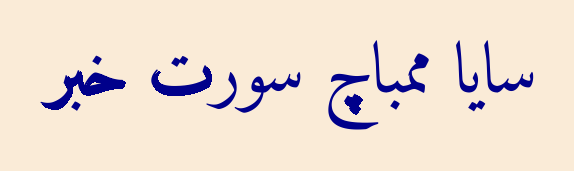

In [7]:
ink = image_to_ink(clean(TEXT))
ink_to_image(
    Blot(distance=3).apply(ink, np.random.default_rng(1)), foreground="darkblue", background="antiquewhite", mode="RGB"
)